# Ads Spend Sources

> **Disclaimer:** Aug 2018 (13 of 31 days) and May 2019 (3 of 31 days) are incomplete months and are
> **removed from this analysis**. All results cover the complete months Sep 2018 to Apr 2019.

**Data:** `fact_daily_consumer_ads_spend` joined to `dim_date` on `date`.

**Questions** (numbered as in the summary document)
1. Ad spend source: 1a region over time, 1b top region each month, 1c ad product
2. Ad placement: 2a spend by placement, 2b ad product by placement
3. Impressions and CPM: 3a impressions vs CPM, 3b customers vs impressions per customer
4. Account spend: 4a account attribution, 4b distribution across identified accounts, 4c top 10 identified accounts

**Definitions**
- Ads spend = `impressions * cpm / 1000`, rounded to 1 decimal per row.
- CPM = `total ads spend * 1000 / total impressions`, calculated after aggregating.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from google.cloud import bigquery

PROJECT = 'takehome-511200'
FACT = f'`{PROJECT}.dbt_ads_monetization_fact_ads.fact_daily_consumer_ads_spend`'
DIM_DATE = f'`{PROJECT}.dbt_ads_monetization_dim_ads.dim_date`'

client = bigquery.Client(project=PROJECT)


def run_query(sql, params=None):
    job_config = bigquery.QueryJobConfig(query_parameters=params or [])
    return client.query(sql, job_config=job_config).to_dataframe(create_bqstorage_client=False)


# Number formats: money as $K / $M / $B, counts as K / M / B
def fmt_money(v):
    if pd.isna(v):
        return '-'
    if abs(v) >= 1e9:
        return f'${v / 1e9:,.2f}B'
    if abs(v) >= 1e6:
        return f'${v / 1e6:,.2f}M'
    if abs(v) >= 1e3:
        return f'${v / 1e3:,.1f}K'
    return f'${v:,.0f}'


def fmt_count(v):
    if pd.isna(v):
        return '-'
    for threshold, suffix in [(1e9, 'B'), (1e6, 'M'), (1e3, 'K')]:
        if abs(v) >= threshold:
            return f'{v / threshold:,.1f}{suffix}'
    return f'{v:,.0f}'


def fmt_cpm(v):
    return '-' if pd.isna(v) else f'${v:,.2f}'


def fmt_pct(v):
    return '-' if pd.isna(v) else f'{v:.1f}%'


# Table styling: white background, bold header, one data-bar color per metric
METRIC_COLORS = {'spend': '#9CC3E6', 'impressions': '#A9D8A0', 'cpm': '#F8C58C', 'accounts': '#CDB8E3'}


def white_table(df, formats=None, hide_index=True):
    styler = (
        df.style
        .format(formats or {}, na_rep='-')
        .set_properties(**{'background-color': 'white', 'color': '#222', 'text-align': 'right', 'padding': '4px 10px'})
        .set_table_styles([
            {'selector': 'th', 'props': [('background-color', 'white'), ('color', '#222'), ('font-weight', 'bold'),
                                         ('text-align', 'center'), ('border-bottom', '1.5px solid #444'), ('padding', '4px 10px')]},
            {'selector': 'tr', 'props': [('background-color', 'white')]},
            {'selector': '', 'props': [('border-collapse', 'collapse')]},
        ])
    )
    return styler.hide(axis='index') if hide_index else styler


def metric_bars(styler, spend=(), impressions=(), cpm=(), accounts=(), rows=None):
    for cols, color in [(spend, METRIC_COLORS['spend']), (impressions, METRIC_COLORS['impressions']),
                        (cpm, METRIC_COLORS['cpm']), (accounts, METRIC_COLORS['accounts'])]:
        for col in cols:
            subset = pd.IndexSlice[rows, [col]] if rows is not None else [col]
            styler = styler.bar(subset=subset, color=color, vmin=0, height=70, width=90)
    return styler


PRODUCT_COLORS = {'A': '#4C78A8', 'B': '#F58518', 'C': '#54A24B'}
REGION_COLORS = {'Global': '#222222', 'Two': '#4C78A8', 'One': '#F58518', 'Four': '#54A24B', 'Other': '#9D9D9D'}
PLACEMENT_COLORS = {'Beta': '#4C78A8', 'Gamma': '#F58518', 'Alpha': '#54A24B',
                    'Delta': '#B279A2', 'Epsilon': '#E45756', 'Zeta': '#72B7B2'}
millions = mticker.FuncFormatter(lambda x, _: f'${x / 1e6:,.0f}M')

plt.rcParams.update({
    'font.size': 11,
    'axes.titlesize': 14,
    'axes.titleweight': 'bold',
    'axes.titlelocation': 'left',
    'axes.labelsize': 11,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'figure.dpi': 110,
})

### Analysis period: complete months only

A month is complete when `dim_date` has a row for every day of that month.
`ANALYSIS_FACT` is the fact table joined to `dim_date`, limited to complete months; every query below uses it.

In [2]:
months = run_query(f'''
    SELECT
        month_start_date,
        COUNT(*) AS days_in_data,
        EXTRACT(DAY FROM LAST_DAY(month_start_date)) AS days_in_month
    FROM {DIM_DATE}
    GROUP BY month_start_date
    ORDER BY month_start_date
''')
months['is_complete'] = months['days_in_data'] == months['days_in_month']
complete_months = months.loc[months['is_complete'], 'month_start_date'].tolist()
month_list = ', '.join(f"DATE '{m}'" for m in complete_months)

ANALYSIS_FACT = f'''(
    SELECT
        f.*,
        d.month_start_date
    FROM {FACT} AS f
    JOIN {DIM_DATE} AS d
        ON f.date = d.date
    WHERE d.month_start_date IN ({month_list})
)'''

white_table(
    months.rename(columns={'month_start_date': 'Month', 'days_in_data': 'Days in Data',
                           'days_in_month': 'Days in Month', 'is_complete': 'Included'}),
    {'Month': lambda d: d.strftime('%b %Y'), 'Included': lambda b: 'Yes' if b else 'No (incomplete)'},
)

Month,Days in Data,Days in Month,Included
Aug 2018,13,31,No (incomplete)
Sep 2018,30,30,Yes
Oct 2018,31,31,Yes
Nov 2018,30,30,Yes
Dec 2018,31,31,Yes
Jan 2019,31,31,Yes
Feb 2019,28,28,Yes
Mar 2019,31,31,Yes
Apr 2019,30,30,Yes
May 2019,3,31,No (incomplete)


## 1. Ad spend source

### 1a. Which region has the most ad spend over time, and what is the monthly trend?

**Total ad spend by region**

In [3]:
region_total = run_query(f'''
    SELECT
        region,
        CAST(SUM(ads_spend) AS FLOAT64) AS total_spend,
        SUM(impressions) AS impressions,
        CAST(SUM(ads_spend) * 1000.0 / NULLIF(SUM(impressions), 0) AS FLOAT64) AS cpm
    FROM {ANALYSIS_FACT}
    GROUP BY region
    ORDER BY total_spend DESC
''')
region_total['spend_share_pct'] = 100 * region_total['total_spend'] / region_total['total_spend'].sum()

global_row = pd.DataFrame([{
    'region': 'Global',
    'total_spend': region_total['total_spend'].sum(),
    'impressions': region_total['impressions'].sum(),
    'cpm': region_total['total_spend'].sum() * 1000.0 / region_total['impressions'].sum(),
    'spend_share_pct': 100.0,
}])
region_table = pd.concat([global_row, region_total], ignore_index=True).rename(columns={
    'region': 'Region', 'total_spend': 'Total Spend', 'spend_share_pct': 'Spend Share',
    'impressions': 'Impressions', 'cpm': 'CPM',
})[['Region', 'Total Spend', 'Spend Share', 'Impressions', 'CPM']]
region_rows = region_table.index[1:]
(
    metric_bars(
        white_table(region_table, {'Total Spend': fmt_money, 'Spend Share': fmt_pct, 'Impressions': fmt_count, 'CPM': fmt_cpm}),
        spend=['Total Spend', 'Spend Share'], impressions=['Impressions'], cpm=['CPM'], rows=region_rows,
    )
    .set_properties(subset=pd.IndexSlice[[0], :], **{'font-weight': 'bold', 'border-bottom': '1.5px solid #444'})
)

Region,Total Spend,Spend Share,Impressions,CPM
Global,$62.90M,100.0%,12.0B,$5.26
Two,$30.62M,48.7%,6.3B,$4.90
One,$18.00M,28.6%,1.1B,$16.62
Four,$13.30M,21.2%,4.5B,$2.93
Three,$574.1K,0.9%,37.8M,$15.17
Seven,$127.2K,0.2%,7.2M,$17.59
Eleven,$85.5K,0.1%,4.5M,$19.08
Six,$59.3K,0.1%,11.4M,$5.21
Ten,$53.8K,0.1%,2.4M,$22.81
Nine,$37.9K,0.1%,1.9M,$19.66


**Monthly total ad spend by region** (regions outside the top 3 are grouped as `Other`)

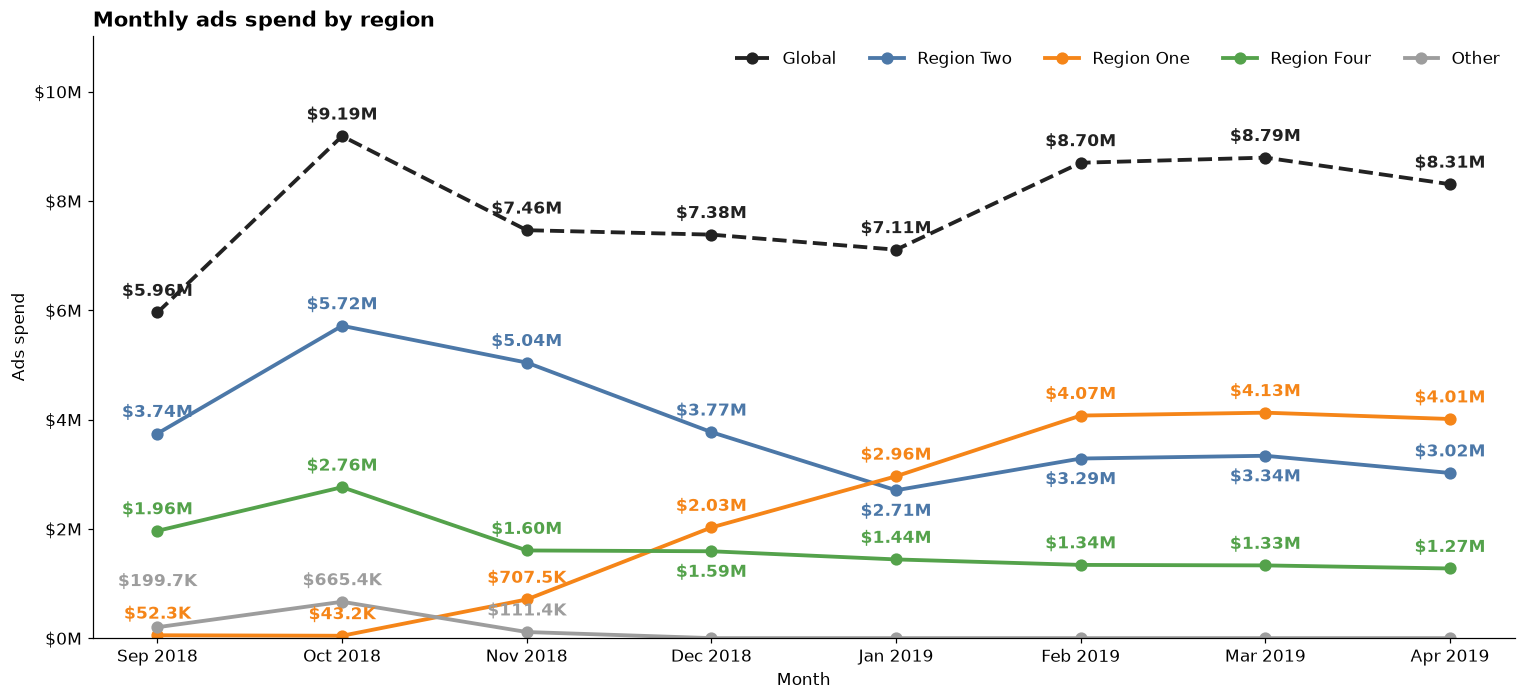

In [4]:
region_month = run_query(f'''
    SELECT
        month_start_date,
        region,
        CAST(SUM(ads_spend) AS FLOAT64) AS total_spend,
        SUM(impressions) AS impressions
    FROM {ANALYSIS_FACT}
    GROUP BY month_start_date, region
''')
region_month['month_start_date'] = pd.to_datetime(region_month['month_start_date'])

top_regions = region_total['region'].head(3).tolist()
region_month['region_group'] = region_month['region'].where(region_month['region'].isin(top_regions), 'Other')
monthly_spend = region_month.pivot_table(
    index='month_start_date', columns='region_group', values='total_spend', aggfunc='sum', fill_value=0
)[top_regions + ['Other']]
monthly_spend.insert(0, 'Global', monthly_spend.sum(axis=1))

fig, ax = plt.subplots(figsize=(14, 6.5))
x = np.arange(len(monthly_spend))
y_max = monthly_spend.to_numpy().max()
close_gap = y_max * 0.09
pad = y_max * 0.025
min_label_gap = y_max * 0.065
for region in monthly_spend.columns:
    label = region if region in ('Global', 'Other') else f'Region {region}'
    ax.plot(x, monthly_spend[region], marker='o', markersize=7, linewidth=2.5, color=REGION_COLORS[region], label=label,
            linestyle='--' if region == 'Global' else '-')

# Data labels: put a label below its point when another line sits just above it (and there is room below);
# otherwise above, nudged up so labels in the same month never overlap.
for i, month_values in enumerate(monthly_spend.itertuples(index=False)):
    points = [(r, v) for r, v in zip(monthly_spend.columns, month_values) if v > 0]
    above = []
    for region, v in points:
        line_just_above = any(0 < other - v < close_gap for _, other in points)
        if line_just_above and v > close_gap * 1.2:
            ax.text(i, v - pad, fmt_money(v), ha='center', va='top', fontsize=11, fontweight='bold', color=REGION_COLORS[region])
        else:
            above.append((region, v))
    last_label_y = -np.inf
    for region, v in sorted(above, key=lambda p: p[1]):
        label_y = max(v + pad, last_label_y + min_label_gap)
        ax.text(i, label_y, fmt_money(v), ha='center', va='bottom', fontsize=11, fontweight='bold', color=REGION_COLORS[region])
        last_label_y = label_y
ax.set_xticks(x)
ax.set_xticklabels(monthly_spend.index.strftime('%b %Y'))
ax.set_ylim(0, y_max * 1.2)
ax.yaxis.set_major_formatter(millions)
ax.set_title('Monthly ads spend by region')
ax.set_xlabel('Month')
ax.set_ylabel('Ads spend')
ax.legend(loc='upper right', ncol=len(monthly_spend.columns), frameon=False, fontsize=11)
plt.tight_layout()
plt.show()

### 1b. Which region has the highest ad spend each month?

In [5]:
monthly_leader = (
    region_month
    .sort_values('total_spend', ascending=False)
    .groupby('month_start_date', as_index=False)
    .head(1)
    .sort_values('month_start_date')
    .reset_index(drop=True)
)
monthly_leader['cpm'] = monthly_leader['total_spend'] * 1000.0 / monthly_leader['impressions']

leader_table = monthly_leader.rename(columns={
    'month_start_date': 'Month', 'region': 'Top Region', 'total_spend': 'Total Spend',
    'impressions': 'Impressions', 'cpm': 'CPM',
})[['Month', 'Top Region', 'Total Spend', 'Impressions', 'CPM']]
(
    metric_bars(
        white_table(leader_table, {'Month': lambda d: d.strftime('%b %Y'), 'Total Spend': fmt_money,
                                   'Impressions': fmt_count, 'CPM': fmt_cpm}),
        spend=['Total Spend'], impressions=['Impressions'], cpm=['CPM'],
    )
    .map(lambda r: f'color: {REGION_COLORS.get(r, "#222")}; font-weight: bold', subset=['Top Region'])
)

Month,Top Region,Total Spend,Impressions,CPM
Sep 2018,Two,$3.74M,938.1M,$3.99
Oct 2018,Two,$5.72M,1.1B,$5.14
Nov 2018,Two,$5.04M,933.6M,$5.40
Dec 2018,Two,$3.77M,790.8M,$4.77
Jan 2019,One,$2.96M,182.9M,$16.20
Feb 2019,One,$4.07M,234.8M,$17.35
Mar 2019,One,$4.13M,256.3M,$16.09
Apr 2019,One,$4.01M,194.4M,$20.62


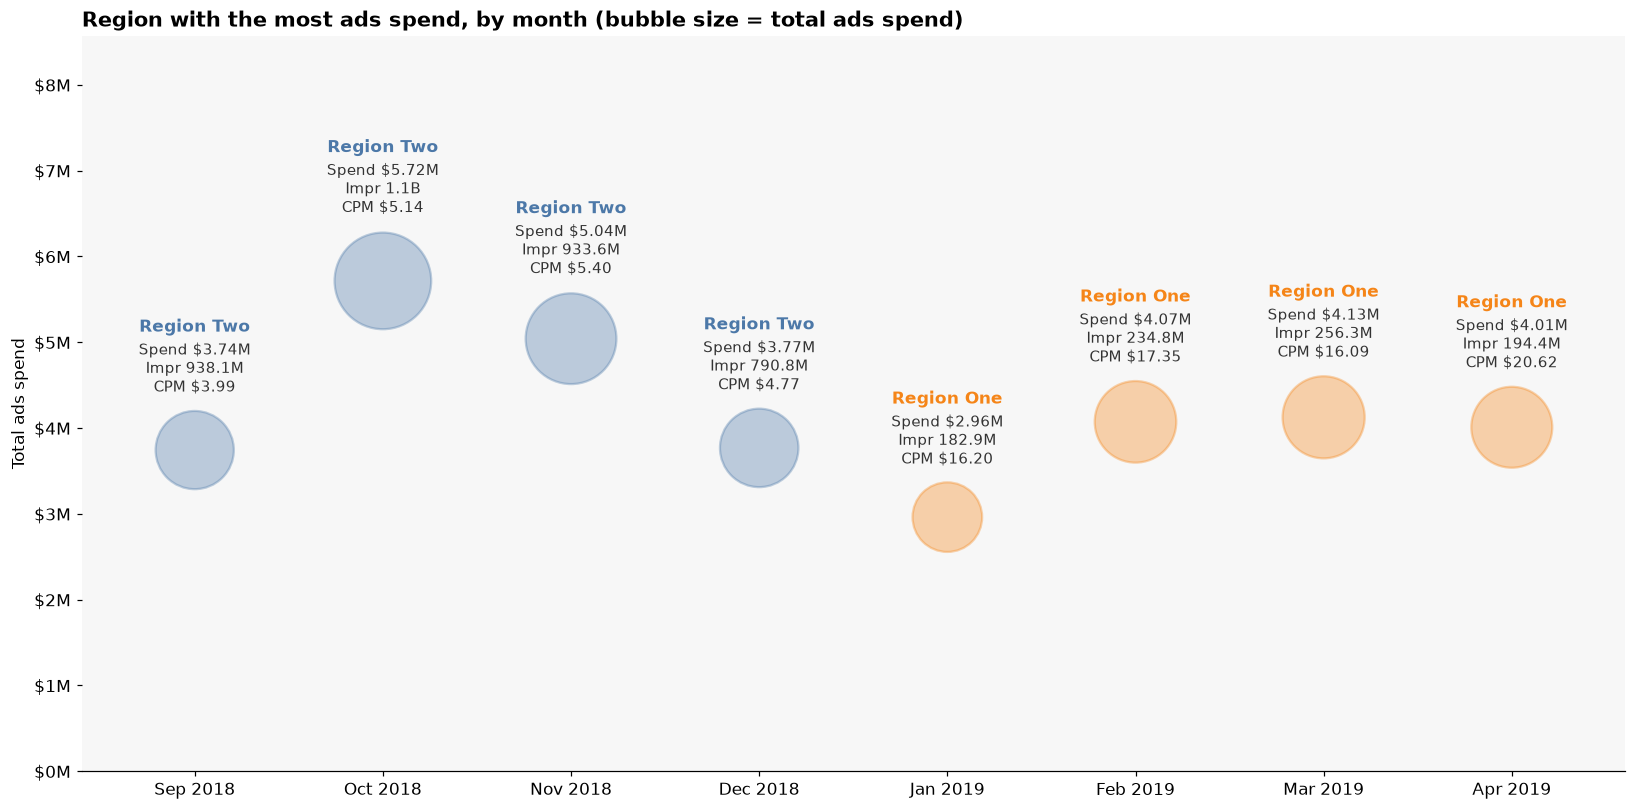

In [6]:
fig, ax = plt.subplots(figsize=(15, 7.5))
ax.set_facecolor('#F7F7F7')
x = np.arange(len(monthly_leader))
sizes = (monthly_leader['total_spend'] / monthly_leader['total_spend'].max() * 4000).to_numpy()
colors = monthly_leader['region'].map(REGION_COLORS)
ax.scatter(x, monthly_leader['total_spend'], s=sizes, c=colors, alpha=0.35, edgecolors=colors, linewidths=1.5)

for i, row in monthly_leader.iterrows():
    radius_pt = (sizes[i] / np.pi) ** 0.5
    ax.annotate(
        f'Region {row.region}',
        (i, row.total_spend), xytext=(0, radius_pt + 46), textcoords='offset points',
        ha='center', va='bottom', fontsize=11, fontweight='bold', color=REGION_COLORS[row.region],
    )
    ax.annotate(
        f'Spend {fmt_money(row.total_spend)}\n'
        f'Impr {fmt_count(row.impressions)}\n'
        f'CPM {fmt_cpm(row.cpm)}',
        (i, row.total_spend), xytext=(0, radius_pt + 6), textcoords='offset points',
        ha='center', va='bottom', fontsize=10, color='#333333',
    )

ax.set_ylim(0, monthly_leader['total_spend'].max() * 1.5)
ax.yaxis.set_major_formatter(millions)
ax.set_xticks(x)
ax.set_xticklabels(monthly_leader['month_start_date'].dt.strftime('%b %Y'))
ax.set_xlim(-0.6, len(monthly_leader) - 0.4)
ax.set_ylabel('Total ads spend')
ax.set_title('Region with the most ads spend, by month (bubble size = total ads spend)')
ax.spines['left'].set_visible(False)
plt.tight_layout()
plt.show()

### 1c. Which product contributed the most ad spend?

Share of each column's ad spend by ad product.
Blue cells are at least 5 percentage points **above** the global share; amber cells are at least 5 points **below** it.

In [7]:
region_product = run_query(f'''
    SELECT
        region,
        ad_product_category,
        CAST(SUM(ads_spend) AS FLOAT64) AS total_spend
    FROM {ANALYSIS_FACT}
    GROUP BY region, ad_product_category
''')
region_product['region_group'] = region_product['region'].where(
    region_product['region'].isin(top_regions), 'Rest of regions'
)

product_spend = region_product.pivot_table(
    index='ad_product_category', columns='region_group', values='total_spend', aggfunc='sum', fill_value=0
)
product_spend.insert(0, 'Global', product_spend.sum(axis=1))
product_spend = product_spend[['Global'] + top_regions + ['Rest of regions']]
product_spend.columns = ['Global'] + [f'Region {r}' for r in top_regions] + ['Rest of regions']

product_share = product_spend.div(product_spend.sum(axis=0), axis=1).mul(100)
product_share.index = [f'Product {p}' for p in product_share.index]
product_share.columns.name = 'Ad Product'
share_rows = product_share.index.tolist()
product_share.loc['Total Spend'] = product_spend.sum(axis=0).to_numpy()
difference = product_share.loc[share_rows].sub(product_share.loc[share_rows, 'Global'], axis=0)


def highlight_vs_global(_):
    styles = pd.DataFrame('', index=product_share.index, columns=product_share.columns)
    above = 'background-color: #CFE2F3; color: #1F4E79; font-weight: bold'
    below = 'background-color: #FCE5CD; color: #7F4F00; font-weight: bold'
    styles.loc[share_rows] = np.select([difference.ge(5), difference.le(-5)], [above, below], '')
    return styles


(
    white_table(product_share, hide_index=False)
    .format(fmt_pct, subset=pd.IndexSlice[share_rows, :])
    .format(fmt_money, subset=pd.IndexSlice[['Total Spend'], :])
    .apply(highlight_vs_global, axis=None)
    .set_properties(subset=pd.IndexSlice[:, ['Global']], **{'border-right': '1.5px solid #444', 'font-weight': 'bold'})
    .set_properties(subset=pd.IndexSlice[['Total Spend'], :], **{'border-top': '1.5px solid #444', 'font-weight': 'bold'})
)

Ad Product,Global,Region Two,Region One,Region Four,Rest of regions
Product A,90.0%,88.9%,99.4%,84.7%,22.9%
Product B,10.0%,11.1%,0.6%,15.3%,77.1%
Product C,0.0%,0.0%,0.0%,0.0%,0.0%
Total Spend,$62.90M,$30.62M,$18.00M,$13.30M,$976.4K


## 2. Ad placement contribution to ad spend

### 2a. Which ad placements generate the most total ad spend?

In [8]:
placement_total = run_query(f'''
    SELECT
        ad_placement,
        CAST(SUM(ads_spend) AS FLOAT64) AS total_spend,
        SUM(impressions) AS impressions,
        CAST(SUM(ads_spend) * 1000.0 / NULLIF(SUM(impressions), 0) AS FLOAT64) AS cpm
    FROM {ANALYSIS_FACT}
    GROUP BY ad_placement
    ORDER BY total_spend DESC
''')
placement_total['spend_share_pct'] = 100 * placement_total['total_spend'] / placement_total['total_spend'].sum()
placement_total['impression_share_pct'] = 100 * placement_total['impressions'] / placement_total['impressions'].sum()

placement_table = placement_total.rename(columns={
    'ad_placement': 'Ad Placement', 'total_spend': 'Total Spend', 'spend_share_pct': 'Spend Share',
    'impressions': 'Impressions', 'impression_share_pct': 'Impression Share', 'cpm': 'CPM',
})[['Ad Placement', 'Total Spend', 'Spend Share', 'Impressions', 'Impression Share', 'CPM']]
metric_bars(
    white_table(placement_table, {'Total Spend': fmt_money, 'Spend Share': fmt_pct, 'Impressions': fmt_count,
                                  'Impression Share': fmt_pct, 'CPM': fmt_cpm}),
    spend=['Total Spend', 'Spend Share'], impressions=['Impressions', 'Impression Share'], cpm=['CPM'],
)

Ad Placement,Total Spend,Spend Share,Impressions,Impression Share,CPM
Beta,$55.27M,87.9%,11.1B,92.9%,$4.98
Gamma,$4.35M,6.9%,411.6M,3.4%,$10.58
Alpha,$3.27M,5.2%,434.5M,3.6%,$7.53
Delta,$0,0.0%,0,0.0%,-
Epsilon,$0,0.0%,0,0.0%,-


### 2b. How does the ad product relate to ad placement?

In [9]:
placement_product = run_query(f'''
    SELECT
        ad_product_category,
        ad_placement,
        CAST(SUM(ads_spend) AS FLOAT64) AS total_spend
    FROM {ANALYSIS_FACT}
    GROUP BY ad_product_category, ad_placement
''')
placements_with_spend = placement_total.loc[placement_total['total_spend'] > 0, 'ad_placement'].tolist()
spend_by_product = (
    placement_product
    .pivot_table(index='ad_product_category', columns='ad_placement', values='total_spend', aggfunc='sum', fill_value=0)
    .reindex(columns=placements_with_spend, fill_value=0)
)

product_placement_table = spend_by_product.copy()
product_placement_table.index = [f'Product {p}' for p in product_placement_table.index]
product_placement_table['Total'] = product_placement_table.sum(axis=1)
product_placement_table.columns.name = 'Ad Product'
metric_bars(
    white_table(product_placement_table, {c: fmt_money for c in product_placement_table.columns}, hide_index=False),
    spend=list(product_placement_table.columns),
)

Ad Product,Beta,Gamma,Alpha,Total
Product A,$55.17M,$0,$1.45M,$56.62M
Product B,$103.5K,$4.35M,$1.83M,$6.28M
Product C,$0,$0,$0,$0


## 3. Impression and CPM trends

**Driver tree:** Ads spend = Impressions × CPM / 1000, and Impressions = Active customers × Impressions per customer.
So a change in spend comes from **how many customers deliver**, **how many impressions each one gets**, or **the price (CPM)**.

**Segments**
- **Customer 0**: rows with `customer_id = '0'` (always with `account_id = 0`). This is a placeholder, not a single real customer,
  and it holds 73-92% of impressions every month, so it is kept separate and not counted as a customer.
- **Identified customers**: all other customer IDs. Customer counts cover this segment only.

An *active* customer or account is one with at least one impression in the period. All placements are combined.

In [10]:
split_month = pd.Timestamp(complete_months[len(complete_months) // 2])
first_label = f'{pd.Timestamp(complete_months[0]):%b %Y}-{split_month - pd.DateOffset(months=1):%b %Y}'.replace(' 2018-', '-')
second_label = f'{split_month:%b %Y}-{pd.Timestamp(complete_months[-1]):%b %Y}'.replace(' 2019-', '-')
SEGMENT_SQL = "IF(customer_id = '0', 'Customer 0', 'Identified customers')"


def driver_query(period_sql):
    return run_query(f'''
        SELECT
            {period_sql} AS period,
            {SEGMENT_SQL} AS segment,
            CAST(SUM(ads_spend) AS FLOAT64) AS total_spend,
            SUM(impressions) AS impressions,
            COUNT(DISTINCT IF(impressions > 0, customer_id, NULL)) AS active_customers
        FROM {ANALYSIS_FACT}
        GROUP BY period, segment
    ''')


print(f'First half: {first_label}  |  Second half: {second_label}')

First half: Sep-Dec 2018  |  Second half: Jan-Apr 2019


### 3a. Is total ad spend driven by impressions or CPM?

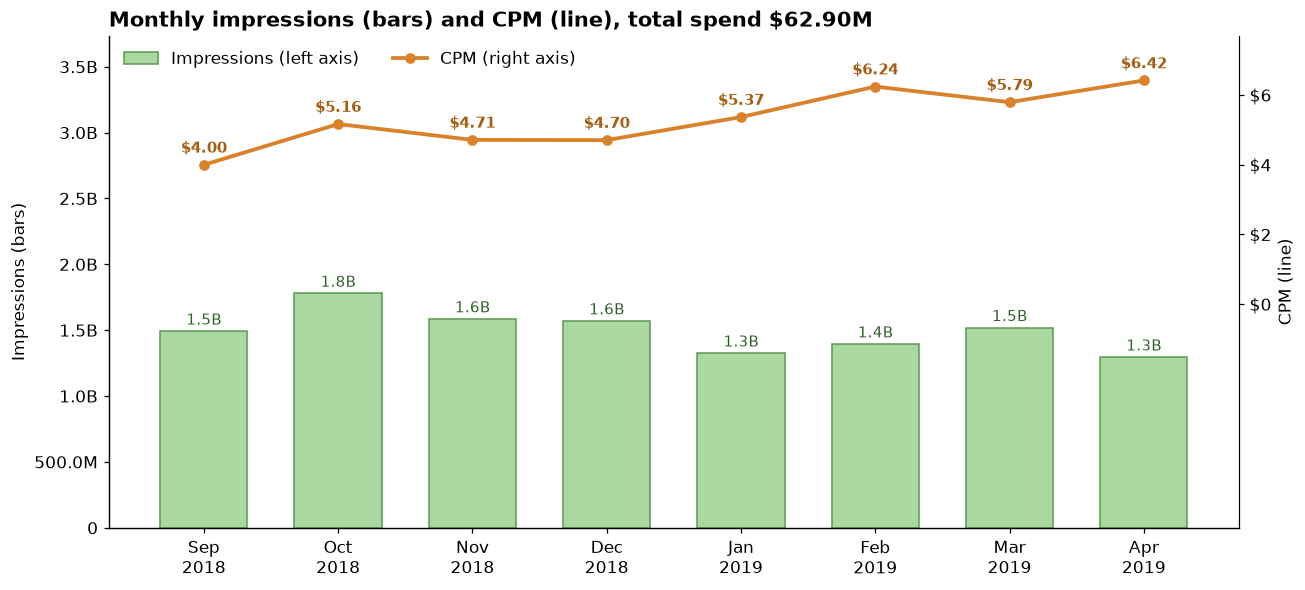

In [11]:
monthly_drivers = driver_query('month_start_date')
monthly_drivers['period'] = pd.to_datetime(monthly_drivers['period'])
monthly_total = monthly_drivers.groupby('period')[['total_spend', 'impressions']].sum().reindex(pd.to_datetime(sorted(complete_months)))
monthly_total['cpm'] = monthly_total['total_spend'] * 1000.0 / monthly_total['impressions']

fig, ax = plt.subplots(figsize=(12, 5.5))
x = np.arange(len(monthly_total))
bars = ax.bar(x, monthly_total['impressions'], color=METRIC_COLORS['impressions'], edgecolor='#5B9A50', width=0.65,
              label='Impressions')
ax.bar_label(bars, labels=[fmt_count(v) for v in monthly_total['impressions']], padding=2, fontsize=10, color='#2F5F28')
ax.set_ylim(0, monthly_total['impressions'].max() * 2.1)  # bars use the lower half of the chart
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: fmt_count(v)))
ax.set_xticks(x)
ax.set_xticklabels(monthly_total.index.strftime('%b\n%Y'))
ax.set_ylabel('Impressions (bars)')

cpm_ax = ax.twinx()
cpm_max = monthly_total['cpm'].max()
cpm_ax.plot(x, monthly_total['cpm'], color='#D9822B', marker='o', linewidth=2.5, label='CPM')
for i, v in enumerate(monthly_total['cpm']):
    cpm_ax.annotate(fmt_cpm(v), (i, v), xytext=(0, 8), textcoords='offset points',
                    ha='center', fontsize=10, fontweight='bold', color='#A65E12')
cpm_ax.set_ylim(-cpm_max, cpm_max * 1.2)  # CPM line uses the upper half
cpm_ax.set_yticks([t for t in cpm_ax.get_yticks() if 0 <= t <= cpm_max * 1.2])
cpm_ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f'${v:,.0f}'))
cpm_ax.set_ylabel('CPM (line)')
cpm_ax.spines['right'].set_visible(True)
cpm_ax.spines['top'].set_visible(False)

ax.set_title(f'Monthly impressions (bars) and CPM (line), total spend {fmt_money(monthly_total["total_spend"].sum())}')
handles = ax.get_legend_handles_labels()[0] + cpm_ax.get_legend_handles_labels()[0]
cpm_ax.legend(handles, ['Impressions (left axis)', 'CPM (right axis)'], loc='upper left', ncol=2, frameon=False, fontsize=11)
plt.tight_layout()
plt.show()

### 3b. Is the change driven by more customers or more impressions per customer?

**Monthly impressions and CPM by customer group** (for identified customers, spend = active customers × impressions per customer × CPM / 1000)

In [12]:
by_segment = monthly_drivers.pivot_table(index='period', columns='segment',
                                         values=['total_spend', 'impressions', 'active_customers'],
                                         aggfunc='sum', fill_value=0)

total_spend = by_segment['total_spend'].sum(axis=1)
total_impressions = by_segment['impressions'].sum(axis=1)
ident_spend = by_segment[('total_spend', 'Identified customers')]
ident_impr = by_segment[('impressions', 'Identified customers')]
ident_customers = by_segment[('active_customers', 'Identified customers')]
cust0_spend = by_segment[('total_spend', 'Customer 0')]
cust0_impr = by_segment[('impressions', 'Customer 0')]

monthly_driver_table = pd.DataFrame({
    ('All spend', 'Total Spend'): total_spend,
    ('All spend', 'Impressions'): total_impressions,
    ('All spend', 'CPM'): total_spend * 1000.0 / total_impressions,
    ('Customer 0', 'Share of Impressions'): 100 * cust0_impr / total_impressions,
    ('Customer 0', 'CPM'): cust0_spend * 1000.0 / cust0_impr,
    ('Identified customers', 'Active Customers'): ident_customers,
    ('Identified customers', 'Impr / Customer'): ident_impr / ident_customers,
    ('Identified customers', 'CPM'): ident_spend * 1000.0 / ident_impr,
})
monthly_driver_table.index = monthly_driver_table.index.strftime('%b %Y')
monthly_driver_table.index.name = None
monthly_driver_table.columns.names = [None, 'Month']

formats = {}
for col in monthly_driver_table.columns:
    name = col[1]
    if name == 'Total Spend':
        formats[col] = fmt_money
    elif name in ('Impressions', 'Impr / Customer'):
        formats[col] = fmt_count
    elif name == 'CPM':
        formats[col] = fmt_cpm
    elif name.startswith('Share'):
        formats[col] = fmt_pct
    else:
        formats[col] = '{:,.0f}'

(
    metric_bars(
        white_table(monthly_driver_table, formats, hide_index=False),
        spend=[('All spend', 'Total Spend')],
        impressions=[('All spend', 'Impressions'), ('Identified customers', 'Impr / Customer')],
        cpm=[('All spend', 'CPM'), ('Identified customers', 'CPM')],
        accounts=[('Identified customers', 'Active Customers')],
    )
    .set_properties(subset=[('Customer 0', 'Share of Impressions'), ('Identified customers', 'Active Customers')],
                    **{'border-left': '1.5px solid #444'})
)

**Identified customers: retained, lost and new between the two halves**

In [13]:
customer_halves = run_query(f'''
    SELECT
        customer_id,
        SUM(IF(month_start_date < @split, impressions, 0)) AS impressions_first,
        SUM(IF(month_start_date >= @split, impressions, 0)) AS impressions_second,
        CAST(SUM(IF(month_start_date >= @split, ads_spend, 0)) AS FLOAT64) AS spend_second
    FROM {ANALYSIS_FACT}
    WHERE customer_id != '0'
    GROUP BY customer_id
''', params=[bigquery.ScalarQueryParameter('split', 'DATE', split_month.date())])
active_first = customer_halves['impressions_first'] > 0
active_second = customer_halves['impressions_second'] > 0
customer_halves['status'] = np.select(
    [active_first & active_second, active_first & ~active_second, ~active_first & active_second],
    ['Retained', 'Lost', 'New'], 'Inactive',
)

counts = customer_halves['status'].value_counts()
new_spend = customer_halves.loc[customer_halves['status'] == 'New', 'spend_second'].sum()
churn_table = pd.DataFrame([{
    f'Active {first_label}': counts.get('Retained', 0) + counts.get('Lost', 0),
    f'Active {second_label}': counts.get('Retained', 0) + counts.get('New', 0),
    'Retained': counts.get('Retained', 0),
    'Lost': counts.get('Lost', 0),
    'New': counts.get('New', 0),
    f'{second_label} Spend from New Customers': new_spend,
    'New Customer Share of Spend': 100 * new_spend / customer_halves['spend_second'].sum(),
}])
count_cols = [c for c in churn_table.columns if c.startswith('Active') or c in ('Retained', 'Lost', 'New')]
white_table(churn_table, {**{c: '{:,.0f}' for c in count_cols},
                          f'{second_label} Spend from New Customers': fmt_money,
                          'New Customer Share of Spend': fmt_pct})

Active Sep-Dec 2018,Active Jan-Apr 2019,Retained,Lost,New,Jan-Apr 2019 Spend from New Customers,New Customer Share of Spend
232,34,4,228,30,$9.31M,61.4%


## 4. Distribution of account spend

### 4a. How much ad spend can be attributed to an account?

In [14]:
account_spend = run_query(f'''
    SELECT
        account_id,
        CAST(SUM(ads_spend) AS FLOAT64) AS total_spend,
        SUM(impressions) AS impressions,
        COUNT(DISTINCT customer_id) AS customers
    FROM {ANALYSIS_FACT}
    GROUP BY account_id
''')
account_spend['account_group'] = np.select(
    [account_spend['account_id'].isna().to_numpy(), account_spend['account_id'].eq(0).fillna(False).to_numpy(bool)],
    ['Missing account ID (NULL)', 'Account ID 0'],
    'Identified accounts',
)

attribution = (
    account_spend
    .groupby('account_group')
    .agg(accounts=('account_id', 'size'), total_spend=('total_spend', 'sum'), impressions=('impressions', 'sum'))
    .reindex(['Identified accounts', 'Account ID 0', 'Missing account ID (NULL)'])
    .reset_index()
)
attribution.loc[attribution['account_group'] != 'Identified accounts', 'accounts'] = np.nan
attribution['spend_share_pct'] = 100 * attribution['total_spend'] / attribution['total_spend'].sum()
attribution['cpm'] = attribution['total_spend'] * 1000.0 / attribution['impressions']

attribution_table = attribution.rename(columns={
    'account_group': 'Account Group', 'accounts': 'Accounts', 'total_spend': 'Total Spend',
    'spend_share_pct': 'Spend Share', 'impressions': 'Impressions', 'cpm': 'CPM',
})[['Account Group', 'Accounts', 'Total Spend', 'Spend Share', 'Impressions', 'CPM']]
metric_bars(
    white_table(attribution_table, {'Accounts': '{:,.0f}', 'Total Spend': fmt_money, 'Spend Share': fmt_pct,
                                    'Impressions': fmt_count, 'CPM': fmt_cpm}),
    spend=['Total Spend', 'Spend Share'], impressions=['Impressions'], cpm=['CPM'],
)

Account Group,Accounts,Total Spend,Spend Share,Impressions,CPM
Identified accounts,"1,031",$25.55M,40.6%,1.9B,$13.21
Account ID 0,-,$37.24M,59.2%,10.0B,$3.72
Missing account ID (NULL),-,$103.5K,0.2%,3.5M,$29.76


Spend with account ID 0 or a missing account ID cannot be tied to an account, so the rest of this section
covers **identified accounts only**.

### 4b. How is ad spend distributed across identified accounts?

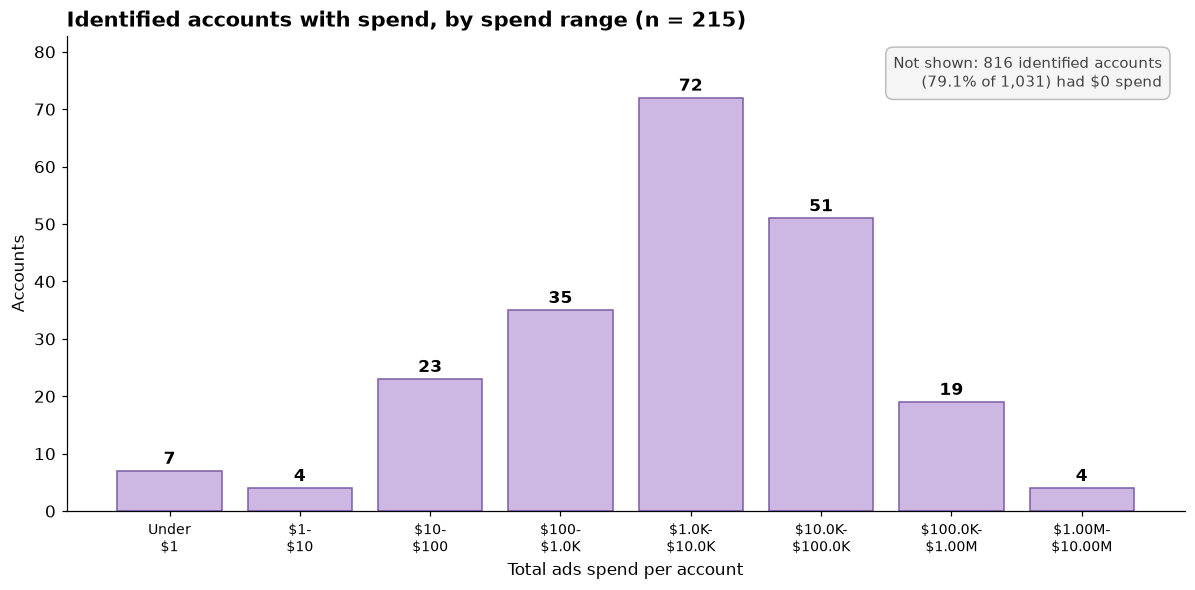

In [15]:
identified = account_spend[account_spend['account_group'] == 'Identified accounts'].copy()
identified_total = identified['total_spend'].sum()
spenders = identified[identified['total_spend'] > 0].sort_values('total_spend', ascending=False).reset_index(drop=True)

# Histogram on a log scale
fig, ax = plt.subplots(figsize=(11, 5.5))
low = np.floor(np.log10(spenders['total_spend'].min()))
high = np.ceil(np.log10(spenders['total_spend'].max()))
edges = 10 ** np.arange(low, high + 1)
counts, _ = np.histogram(spenders['total_spend'], bins=edges)
x = np.arange(len(counts))
bars = ax.bar(x, counts, color=METRIC_COLORS['accounts'], edgecolor='#7B5BA6', width=0.8)
ax.bar_label(bars, padding=2, fontsize=11, fontweight='bold')
ax.set_xticks(x)
range_labels = [f'{fmt_money(a)}-\n{fmt_money(b)}' for a, b in zip(edges[:-1], edges[1:])]
range_labels[0] = f'Under\n{fmt_money(edges[1])}'
ax.set_xticklabels(range_labels, fontsize=9)
ax.set_ylim(0, counts.max() * 1.15)
ax.set_title(f'Identified accounts with spend, by spend range (n = {len(spenders):,})')
zero_spend_accounts = int((identified['total_spend'] == 0).sum())
ax.text(0.98, 0.96,
        f'Not shown: {zero_spend_accounts:,} identified accounts\n'
        f'({100 * zero_spend_accounts / len(identified):.1f}% of {len(identified):,}) had $0 spend',
        transform=ax.transAxes, ha='right', va='top', fontsize=10, color='#424242',
        bbox={'boxstyle': 'round,pad=0.5', 'facecolor': '#F5F5F5', 'edgecolor': '#BDBDBD'})
ax.set_xlabel('Total ads spend per account')
ax.set_ylabel('Accounts')
plt.tight_layout()
plt.show()

### 4c. Who are the top 10 identified accounts?

In [16]:
top_accounts = spenders.head(10).copy()
top_accounts['rank'] = np.arange(1, len(top_accounts) + 1)
top_accounts['share_pct'] = 100 * top_accounts['total_spend'] / identified_total
top_accounts['cpm'] = top_accounts['total_spend'] * 1000.0 / top_accounts['impressions']
top_table = top_accounts.rename(columns={
    'rank': 'Rank', 'account_id': 'Account ID', 'total_spend': 'Total Spend', 'share_pct': 'Share of Identified Spend',
    'impressions': 'Impressions', 'cpm': 'CPM', 'customers': 'Customers',
})[['Rank', 'Account ID', 'Total Spend', 'Share of Identified Spend', 'Impressions', 'CPM', 'Customers']]
metric_bars(
    white_table(top_table, {'Account ID': '{:d}', 'Total Spend': fmt_money, 'Share of Identified Spend': fmt_pct,
                            'Impressions': fmt_count, 'CPM': fmt_cpm}),
    spend=['Total Spend', 'Share of Identified Spend'], impressions=['Impressions'], cpm=['CPM'],
)

Rank,Account ID,Total Spend,Share of Identified Spend,Impressions,CPM,Customers
1,6777,$9.43M,36.9%,635.0M,$14.85,35
2,3363,$5.92M,23.2%,319.1M,$18.57,2
3,3545,$1.89M,7.4%,160.1M,$11.83,2
4,11306,$1.89M,7.4%,71.6M,$26.40,3
5,3248,$518.3K,2.0%,42.7M,$12.13,1
6,2521,$343.9K,1.3%,38.1M,$9.02,2
7,3898,$275.7K,1.1%,20.7M,$13.34,1
8,4399,$248.9K,1.0%,19.9M,$12.49,1
9,3334,$226.6K,0.9%,16.2M,$13.99,1
10,2996,$223.0K,0.9%,23.0M,$9.70,1


## Key findings

Complete months only (Sep 2018 – Apr 2019). Same findings as the summary document.

**1a. Region with the most ad spend over time**
- **Region Two leads:** $30.62M (48.7%) of $62.90M total spend, followed by Region One ($18.00M, 28.6%) and Region Four ($13.30M, 21.2%). Together they make up 98.5% of spend.
- **Prices differ sharply by region:** Region One's CPM is $16.62, versus $4.90 for Region Two and $2.93 for Region Four.
- **Region One overtook Region Two in January 2019.** Region Two peaked at $5.72M in October 2018 and settled at $2.7–3.3M a month in 2019, while Region One grew from under $0.1M a month (Sep–Oct 2018) to $4.0–4.1M a month (Feb–Apr 2019).
- **Region Four declined steadily,** from $2.76M in October 2018 to $1.27M in April 2019.

**1b. Region with the highest ad spend each month**
- **The leader switched mid-period:** Region Two topped every month from September to December 2018, and Region One every month from January to April 2019.
- **They lead in different ways:** Region Two through volume (0.79–1.11B impressions a month at a $3.99–5.40 CPM), Region One through price (182–256M impressions a month at a $16.09–20.62 CPM).

**1c. Product that contributed the most ad spend**
- **Product A drives 90.0% of spend, and product C has none.** The mix varies by region: Region One is almost entirely product A (99.4%), Region Four leans more toward product B (15.3% vs 10.0% globally), and the remaining regions are mostly product B (77.1%).

**2a. Ad placements that generate the most ad spend**
- **Beta generates the most spend:** $55.27M (87.9%) on 92.9% of impressions. Delta and Epsilon have no spend.
- **Beta wins on volume, not price:** its CPM is the lowest at $4.98, compared with $10.58 for Gamma and $7.53 for Alpha.

**2b. Ad product by ad placement**
- **Product A runs almost entirely on Beta:** $55.17M of its $56.62M.
- **Product B is spread across placements:** Gamma ($4.35M, which serves only product B) and Alpha ($1.83M), with little on Beta ($103.5K).

**3a. Impressions vs CPM**
- **Price, not volume, drove ad spend:** CPM rose 60%, from $4.00 in September 2018 to $6.42 in April 2019, while monthly impressions fell from 1.5–1.8B in Sep–Dec 2018 to 1.3–1.5B in Jan–Apr 2019.

**3b. Customers vs impressions per customer**
- **Customer 0 holds most volume at a low, flat price:** 73–92% of impressions every month at a $3.54–3.99 CPM, while identified customers' CPM rose from $6.54 to $20.62.
- **Identified customers shifted from many small to a few large:** active customers fell from 136–137 a month (Oct–Nov 2018) to 4–28, while impressions per customer rose from 1.7–3.5M to 6.9–31.2M. Only 4 of 232 customers were retained; the 30 new customers produced 61.4% of identified-customer spend in Jan–Apr 2019.

**4a. Account attribution**
- **Most spend can't be tied to an account:** only 40.6% ($25.55M) belongs to the 1,031 identified accounts; 59.2% ($37.24M) sits under account ID 0 and 0.2% has no account ID.
- **Account ID 0 is high volume at a low price:** 10.0B impressions at a $3.72 CPM, versus $13.21 for identified accounts.

**4b. Spend distribution across identified accounts**
- **Most identified accounts spent nothing:** 816 of 1,031 (79.1%) had $0 spend, so only 215 appear in the chart.
- **Spending accounts are mostly small:** the most common range is $1K–10K (72 accounts), and only 4 accounts spent more than $1M.

**4c. Top 10 identified accounts**
- **Spend is highly concentrated:** the top 4 accounts hold 74.9% of identified-account spend, and account 6777 alone holds 36.9% ($9.43M).
- **Account 6777 is linked to 35 customers,** which suggests an agency or shared account; the other top accounts serve 1–3 customers.